# Customer Segmentation & Churn Analytics - European Banking
Notebook flow: Day 1 (load, validate, clean, segment) -> Day 2 (churn analysis) -> Day 3 (high-value customers + KPIs)

## DAY 1 - Load, Validate, Clean, Segment
### 1. Import libraries
`pandas` = tables, `numpy` = numbers, `plotly` = interactive charts.

In [1]:
import pandas as pd
import numpy as np
import plotly.express as px
pd.set_option('display.float_format', '{:,.2f}'.format)

### 2. Load the CSV
`df` = DataFrame = Excel-like table.

In [2]:
df = pd.read_csv("European_Bank.csv")   # keep this notebook in the same folder as the CSV
df.head()

,Year,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,2025,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,"101,348.88",1
1,2025,15647311,Hill,608,Spain,Female,41,1,"83,807.86",1,0,1,"112,542.58",0
2,2025,15619304,Onio,502,France,Female,42,8,"159,660.80",3,1,0,"113,931.57",1
3,2025,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,"93,826.63",0
4,2025,15737888,Mitchell,850,Spain,Female,43,2,"125,510.82",1,1,1,"79,084.10",0


In [3]:
df.shape   # (rows, columns)

(10000, 14)

In [4]:
df.info()  # column types and non-empty counts

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Year             10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [5]:
df.describe()  # min / max / mean of number columns -> spot impossible values

,Year,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,"10,000.00","10,000.00","10,000.00","10,000.00","10,000.00","10,000.00","10,000.00","10,000.00","10,000.00","10,000.00","10,000.00"
mean,"2,025.00","15,690,940.57",650.53,38.92,5.01,"76,485.89",1.53,0.71,0.52,"100,090.24",0.20
std,0.00,"71,936.19",96.65,10.49,2.89,"62,397.41",0.58,0.46,0.50,"57,510.49",0.40
min,"2,025.00","15,565,701.00",350.00,18.00,0.00,0.00,1.00,0.00,0.00,11.58,0.00
25%,"2,025.00","15,628,528.25",584.00,32.00,3.00,0.00,1.00,0.00,0.00,"51,002.11",0.00
50%,"2,025.00","15,690,738.00",652.00,37.00,5.00,"97,198.54",1.00,1.00,1.00,"100,193.91",0.00
75%,"2,025.00","15,753,233.75",718.00,44.00,7.00,"127,644.24",2.00,1.00,1.00,"149,388.25",0.00
max,"2,025.00","15,815,690.00",850.00,92.00,10.00,"250,898.09",4.00,1.00,1.00,"199,992.48",1.00


### 3. Validation (can we trust the data?)

In [6]:
print('Missing values:', df.isnull().sum().sum())
print('Duplicate rows:', df.duplicated().sum())
print('CustomerId unique:', df['CustomerId'].is_unique)

Missing values: 0
Duplicate rows: 0
CustomerId unique: True


In [7]:
for col in ['HasCrCard','IsActiveMember','Exited']:   # must be only 0/1
    print(col, sorted(df[col].unique()))
print(df['Geography'].unique(), df['Gender'].unique())

HasCrCard [np.int64(0), np.int64(1)]
IsActiveMember [np.int64(0), np.int64(1)]
Exited [np.int64(0), np.int64(1)]
['France' 'Spain' 'Germany'] ['Female' 'Male']


In [8]:
print(df['NumOfProducts'].value_counts())
print(df['Exited'].value_counts())

NumOfProducts
1    5084
2    4590
3     266
4      60
Name: count, dtype: int64
Exited
0    7963
1    2037
Name: count, dtype: int64


**Findings:** 10,000 rows, no missing values, no duplicates, every binary column has only 0/1, Geography has only France/Spain/Germany, products range 1-4. `Year` column is 2025 for all rows (constant, so useless). **Data is clean.**

### 4. Cleaning
Remove columns that do not help analysis: Surname (project doc says so), CustomerId, Year (constant).

In [9]:
df = df.drop(columns=["Surname","CustomerId","Year","RowNumber"], errors="ignore")
df.columns

Index(['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance',
       'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary',
       'Exited'],
      dtype='object')

### 5. Segments
Grouping customers lets us say *"Germany, age 46-60"* instead of just *"20% churn"*.

In [10]:
df["AgeGroup"] = pd.cut(df["Age"], bins=[0,29,45,60,120], labels=["<30","30-45","46-60","60+"])
df["CreditBand"] = pd.cut(df["CreditScore"], bins=[0,579,669,900], labels=["Low","Medium","High"])
df["TenureGroup"] = pd.cut(df["Tenure"], bins=[-1,2,6,10], labels=["New","Mid-term","Long-term"])

median_bal = df[df["Balance"] > 0]["Balance"].median()   # median of non-zero balances
df["BalanceSegment"] = np.where(df["Balance"] == 0, "Zero-balance",
                        np.where(df["Balance"] < median_bal, "Low-balance", "High-balance"))
print("Median non-zero balance:", round(median_bal,2))

Median non-zero balance: 119839.69


In [11]:
for col in ["AgeGroup","CreditBand","TenureGroup","BalanceSegment"]:
    print(df[col].value_counts(), "\n")
print("Missing after segmenting:", df.isnull().sum().sum())

AgeGroup
30-45    6248
46-60    1647
<30      1641
60+       464
Name: count, dtype: int64 

CreditBand
High      4307
Medium    3331
Low       2362
Name: count, dtype: int64 

TenureGroup
Mid-term     3977
Long-term    3527
New          2496
Name: count, dtype: int64 

BalanceSegment
Zero-balance    3617
High-balance    3192
Low-balance     3191
Name: count, dtype: int64 

Missing after segmenting: 0


In [12]:
df.to_csv("cleaned_data.csv", index=False)   # used later by the dashboard

## DAY 2 - Churn Analysis
`Exited` is 0/1, so its **mean x 100 = churn %**. That is why `groupby(...).Exited.mean()` is the key tool of this project.

In [13]:
total_churned = df["Exited"].sum()
overall = df["Exited"].mean()*100
print(f"Overall churn rate: {overall:.2f}%  ({total_churned} of {len(df)} customers)")

Overall churn rate: 20.37%  (2037 of 10000 customers)


In [14]:
def churn_table(col):
    g = df.groupby(col, observed=True)["Exited"].agg(Customers="count", Churned="sum", ChurnRate="mean")
    g["ChurnRate"] *= 100
    g["ContributionPct"] = g["Churned"] / total_churned * 100   # share of ALL churners
    g["RiskIndex"] = g["ChurnRate"] / overall                   # >1 = worse than average
    return g
for col in ["Geography","Gender","AgeGroup","CreditBand","TenureGroup","BalanceSegment"]:
    display(churn_table(col))

,Customers,Churned,ChurnRate,ContributionPct,RiskIndex
Geography,,,,,
France,5014,810,16.15,39.76,0.79
Germany,2509,814,32.44,39.96,1.59
Spain,2477,413,16.67,20.27,0.82


,Customers,Churned,ChurnRate,ContributionPct,RiskIndex
Gender,,,,,
Female,4543,1139,25.07,55.92,1.23
Male,5457,898,16.46,44.08,0.81


,Customers,Churned,ChurnRate,ContributionPct,RiskIndex
AgeGroup,,,,,
<30,1641,124,7.56,6.09,0.37
30-45,6248,956,15.30,46.93,0.75
46-60,1647,842,51.12,41.34,2.51
60+,464,115,24.78,5.65,1.22


,Customers,Churned,ChurnRate,ContributionPct,RiskIndex
CreditBand,,,,,
Low,2362,520,22.02,25.53,1.08
Medium,3331,685,20.56,33.63,1.01
High,4307,832,19.32,40.84,0.95


,Customers,Churned,ChurnRate,ContributionPct,RiskIndex
TenureGroup,,,,,
New,2496,528,21.15,25.92,1.04
Mid-term,3977,821,20.64,40.30,1.01
Long-term,3527,688,19.51,33.78,0.96


,Customers,Churned,ChurnRate,ContributionPct,RiskIndex
BalanceSegment,,,,,
High-balance,3192,772,24.19,37.90,1.19
Low-balance,3191,765,23.97,37.56,1.18
Zero-balance,3617,500,13.82,24.55,0.68


### Churned vs Retained profile

In [15]:
df.groupby("Exited")[["Age","Balance","CreditScore","EstimatedSalary","Tenure","NumOfProducts","IsActiveMember"]].mean()

,Age,Balance,CreditScore,EstimatedSalary,Tenure,NumOfProducts,IsActiveMember
Exited,,,,,,,
0,37.41,"72,745.30",651.85,"99,738.39",5.03,1.54,0.55
1,44.84,"91,108.54",645.35,"101,465.68",4.93,1.48,0.36


### Gender, Geography x Age, engagement, products

,Customers,Churned,ChurnRate,ContributionPct,RiskIndex
IsActiveMember,,,,,
0,4849,1302,26.85,63.92,1.32
1,5151,735,14.27,36.08,0.70


,Customers,Churned,ChurnRate,ContributionPct,RiskIndex
NumOfProducts,,,,,
1,5084,1409,27.71,69.17,1.36
2,4590,348,7.58,17.08,0.37
3,266,220,82.71,10.80,4.06
4,60,60,100.00,2.95,4.91


AgeGroup,<30,30-45,46-60,60+
Geography,,,,
France,5.20,11.90,45.80,19.90
Germany,12.60,25.30,67.30,38.90
Spain,7.90,12.50,40.70,20.80


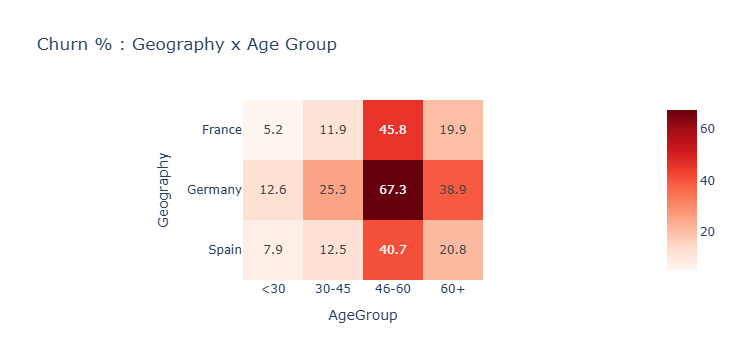

In [16]:
display(churn_table("IsActiveMember"))
display(churn_table("NumOfProducts"))
heat = df.pivot_table(index="Geography", columns="AgeGroup", values="Exited", aggfunc="mean", observed=True)*100
display(heat.round(1))
px.imshow(heat.round(1), text_auto=True, color_continuous_scale="Reds", title="Churn % : Geography x Age Group")

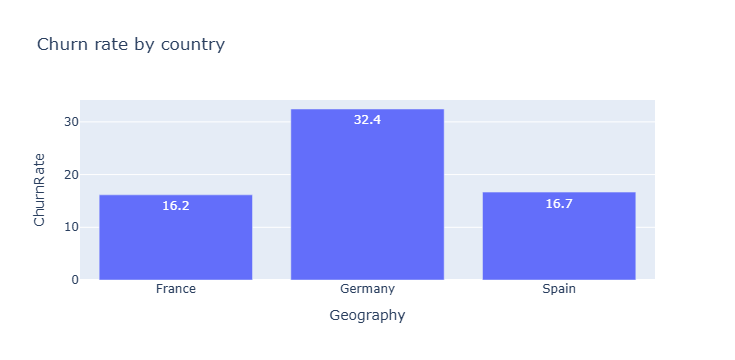

In [17]:
g = churn_table("Geography").reset_index()
px.bar(g, x="Geography", y="ChurnRate", text_auto=".1f", title="Churn rate by country")

**Insights:** Germany churns ~2x France/Spain. Age 46-60 churns ~51%. Women churn more than men. Inactive members churn ~2x active ones. 3-4 product customers almost all leave. Credit score, tenure and salary barely matter.

## DAY 3 - High-Value Customers and KPIs

In [18]:
q75 = df["Balance"].quantile(0.75)
high = df[df["Balance"] > q75]          # top 25% by balance = high-value
print("High-value threshold: EUR", round(q75))
print("High-value churn ratio:", round(high["Exited"].mean()*100,2), "%")
print("Other customers churn :", round(df[df["Balance"]<=q75]["Exited"].mean()*100,2), "%")
at_risk = df[df["Exited"]==1]["Balance"].sum()
print("Balance lost to churn : EUR", f"{at_risk:,.0f}", "=", round(at_risk/df["Balance"].sum()*100,2), "% of all balances")
print("High-value churners hold", round(high[high.Exited==1]["Balance"].sum()/at_risk*100,1), "% of lost balance")

High-value threshold: EUR 127644
High-value churn ratio: 23.68 %
Other customers churn : 19.27 %
Balance lost to churn : EUR 185,588,095 = 24.26 % of all balances
High-value churners hold 47.8 % of lost balance


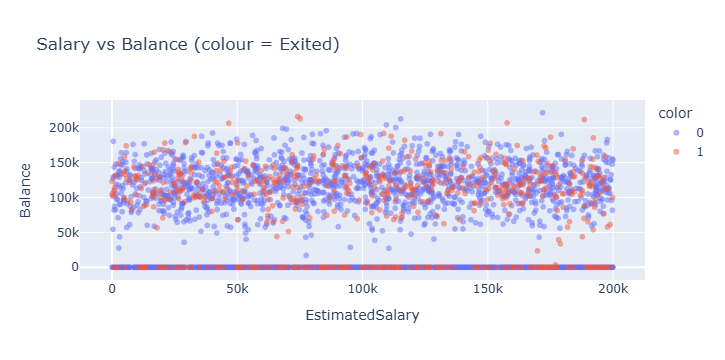

In [19]:
px.scatter(df.sample(3000, random_state=1), x="EstimatedSalary", y="Balance", color=df.sample(3000, random_state=1)["Exited"].astype(str), opacity=0.5, title="Salary vs Balance (colour = Exited)")

In [20]:
df["SalaryBand"] = pd.qcut(df["EstimatedSalary"], 4, labels=["Q1 low","Q2","Q3","Q4 high"])
display(churn_table("SalaryBand"))   # salary does not drive churn

,Customers,Churned,ChurnRate,ContributionPct,RiskIndex
SalaryBand,,,,,
Q1 low,2500,500,20.00,24.55,0.98
Q2,2500,495,19.80,24.30,0.97
Q3,2500,503,20.12,24.69,0.99
Q4 high,2500,539,21.56,26.46,1.06


### The 5 KPIs

In [21]:
kpi = {}
kpi["Overall Churn Rate (%)"] = overall
kpi["High-Value Churn Ratio (%)"] = high["Exited"].mean()*100
gri = (df.groupby("Geography")["Exited"].mean()*100) / overall
for c, v in gri.items(): kpi[f"Geographic Risk Index - {c}"] = v
act = df.groupby("IsActiveMember")["Exited"].mean()*100
kpi["Churn - Inactive (%)"] = act[0]; kpi["Churn - Active (%)"] = act[1]
kpi["Engagement Drop Indicator (inactive / active)"] = act[0]/act[1]
pd.Series(kpi, name="Value").round(2).to_frame()

,Value
Overall Churn Rate (%),20.37
High-Value Churn Ratio (%),23.68
Geographic Risk Index - France,0.79
Geographic Risk Index - Germany,1.59
Geographic Risk Index - Spain,0.82
Churn - Inactive (%),26.85
Churn - Active (%),14.27
Engagement Drop Indicator (inactive / active),1.88


Segment Churn Rate (KPI 2) = the `ChurnRate` column of every `churn_table` above.